<a href="https://colab.research.google.com/github/John-Tenkorang-Anim/Coding/blob/main/Flaming_Dragons_INFO2950.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Phase II: Exploratory Data Analysis and Preregistration**

## **Part 1: Data Collection and Exploratory Data Analysis**

###Research Question

**Main research question.** Among US theatrical films released 2015–2025, how does **pre-release online attention** correspond to **worldwide box-office gross** and **audience satisfaction**? Attention means English-Wikipedia pageviews and/or Google search interest in the **28 days before US release**. Audience satisfaction is average rating for the movie using TMDb.





## **Data Collection**


We collected data on films with US theatrical releases between 2015 and
2025 to examine the relationship between pre-release online attention
and worldwide box-office revenue.

Each film is identified by its TMDb movie ID.

#### Data sources

| Source | Information collected |
|---|---|
| TMDb | Film titles, release dates, budgets, revenue, ratings, and genres |
| Wikipedia | English Wikipedia pageviews during the 28 days before US theatrical release |
| Google Trends | US search interest during the same 28-day period |
| The Numbers | Worldwide box-office revenue for films with reliable title and year matches |

#### Collection procedure

1. Identify popular US theatrical releases from 2015–2025 using TMDb.

2. Collect film details and international release histories.

3. Match each film to its English Wikipedia article. Collect pageviews
   from 28 days before US release through the day before release.

4. Collect Google Trends interest during the same period. Compare each
   film with the anchor term “movie trailers” to calculate a relative
   search-interest ratio. This ratio is not a count of searches.

5. Collect worldwide revenue from The Numbers when a reliable film
   match is available.

6. Save the collected data as CSV files. Record unsuccessful collection
   attempts using status fields rather than replacing them with zero.

The API collection process is documented in a separate notebook.
The cells below clean the saved files without repeating collection.

[Collection notebook](https://colab.research.google.com/drive/1BdKfEpWCJtRN_4ExH5XEi9H5XRun_GhP)

#### Accessing the Data
Steps to run locally:
1. Get raw csv files [Cornell Google Drive: movie_hype_research/decade_2015_2025/raw]
(https://drive.google.com/drive/folders/1PMYU_Da9UoAuf5Vckpi3Bfl9G_4VXJvW?usp=sharing)

![Alternative Text](https://i.postimg.cc/bZHYpymY/Screenshot-2026-10-16-at-12-02-26-PM.png)


2. Create these folders in your Google Drive:

   `My Drive/movie_hype_research/decade_2015_2025`


3. Click raw -> Organize -> Add shortcut

![Alternative Text](https://i.postimg.cc/XrcN4jsn/Screenshot-2026-10-16-at-12-02-48-PM.png)

4. Click "Add" button on "decade_2015_2025". If it doesn't show up as suggested, add it to "My Drive/movie_hype_research/ decade_2015_2025"


![Alternative Text](https://i.postimg.cc/Yvf2MrdS/Screenshot-2026-10-16-at-12-02-57-PM.png)


5. Run the following cell and authorize Google Drive access.

In [ ]:
import re
import unicodedata

import numpy as np
import pandas as pd

from pathlib import Path
from google.colab import drive
from IPython.display import display

drive.mount('/content/drive')

project_folder = Path('/content/drive/MyDrive/movie_hype_research')
dataset_folder = project_folder / 'decade_2015_2025'
raw_folder = dataset_folder / 'raw'

pd.set_option('display.max_columns', 60)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## **Data Cleaning**

#### Step 1: Load the Collected Data

Load the film details, release histories, Wikipedia article matches,
Wikipedia pageviews, and Google Trends results.

Convert movie IDs to integers so that records can be combined consistently.


In [ ]:
def load_movie_data(filename):
    data_df = pd.read_csv(raw_folder / filename)

    data_df['movie_id'] = pd.to_numeric(
        data_df['movie_id'],
        errors='coerce',)

    data_df = data_df.dropna(subset=['movie_id']).copy()
    data_df['movie_id'] = data_df['movie_id'].astype(int)

    return data_df


movie_details_df = load_movie_data('tmdb_details_decade.csv')
release_dates_df = load_movie_data('tmdb_release_dates.csv')
wiki_articles_df = load_movie_data('wiki_article_mapping_v2.csv')
wiki_pageviews_df = load_movie_data('wiki_pageviews_v2.csv')
google_trends_df = load_movie_data('google_trends_decade.csv')

box_office_path = next(
    (
        folder / 'the_numbers_parsed.csv'
        for folder in [
            raw_folder,
            project_folder / 'raw',
            project_folder
        ]
        if (folder / 'the_numbers_parsed.csv').exists()
    ),None)

box_office_df = (
    pd.read_csv(box_office_path)
    if box_office_path is not None
    else pd.DataFrame())

#### Step 2: Select Eligible Films

Keep films with:

- A valid US theatrical release date.
- A release year between 2015 and 2025.
- A positive reported production budget.
- Positive reported TMDb revenue.
- At least 10 TMDb rating votes.

Zero budget and revenue values are excluded because they may represent
unreported information.

This initial screen requires positive TMDb revenue before revenue from
The Numbers is incorporated.

In [ ]:
numeric_columns = [
    'budget',
    'tmdb_revenue',
    'vote_count',
    'rating',
    'release_year'
]

movie_details_df[numeric_columns] = (
    movie_details_df[numeric_columns]
    .apply(pd.to_numeric, errors='coerce')
)

movie_details_df['us_theatrical_date'] = pd.to_datetime(
    movie_details_df['us_theatrical_date'],
    errors='coerce'
)

eligible_movies = (
    movie_details_df['us_theatrical_date'].notna()
    & movie_details_df['release_year'].between(2015, 2025)
    & movie_details_df['budget'].gt(0)
    & movie_details_df['tmdb_revenue'].gt(0)
    & movie_details_df['vote_count'].ge(10)
)

eligible_movies_df = (
    movie_details_df.loc[eligible_movies]
    .drop_duplicates('movie_id')
    .copy()
)

eligible_movies_df['release_year'] = (
    eligible_movies_df['release_year'].astype(int)
)

#### Step 3: Screen Release Timing

Exclude films that were available for US home viewing before their
US theatrical release.

Also exclude films publicly released anywhere more than 28 days before
their US theatrical release. Festival premieres do not count as public
availability.

This reduces the influence of attention generated after audiences have
already had access to a film.

In [ ]:
release_dates_df['release_type'] = pd.to_numeric(
    release_dates_df['release_type'],
    errors='coerce'
)

release_dates_df['release_date'] = (
    pd.to_datetime(
        release_dates_df['release_date'],
        errors='coerce',
        utc=True,
        format='ISO8601'
    )
    .dt.tz_localize(None)
    .dt.normalize()
)

public_releases_df = release_dates_df.loc[
    release_dates_df['release_type'].between(2, 6)
]

first_public_release = (
    public_releases_df.groupby('movie_id')['release_date']
    .min()
    .rename('first_public_release')
)

us_home_releases_df = release_dates_df.loc[
    release_dates_df['country'].eq('US')
    & release_dates_df['release_type'].isin([4, 5, 6])
]

first_us_home_release = (
    us_home_releases_df.groupby('movie_id')['release_date']
    .min()
    .rename('first_us_home_release')
)

eligible_movies_df = (
    eligible_movies_df
    .merge(first_public_release, on='movie_id', how='left')
    .merge(first_us_home_release, on='movie_id', how='left')
)

eligible_movies_df['days_public_before_us'] = (
    eligible_movies_df['us_theatrical_date']
    - eligible_movies_df['first_public_release']
).dt.days

home_before_theaters = (
    eligible_movies_df['first_us_home_release']
    .lt(eligible_movies_df['us_theatrical_date'])
)

public_before_window = (
    eligible_movies_df['days_public_before_us'].gt(28)
)

eligible_movies_df['release_timing_ok'] = ~(
    home_before_theaters | public_before_window
)

#### Step 4: Select Worldwide Revenue

Use worldwide revenue from The Numbers when a reliable match is available.
Otherwise, use TMDb revenue.

Standardize film titles before matching. First match by title and exact
release year. If no exact match exists, allow a difference of one year
only when there is exactly one candidate.

Exclude conflicting revenue records for the same title and year.
Record the source of each film’s selected revenue.

Notably, after we later go through multiple filters, none of our entries contain "The Numbers" revenue. As such, we will not worry about any potential discrepancies between values in the two sources.

In [ ]:
def normalize_title(value):
    title = unicodedata.normalize('NFKD', str(value)).casefold()

    title = ''.join(
        character
        for character in title
        if not unicodedata.combining(character)
    )

    title = title.replace('&', ' and ')

    return re.sub(r'[^a-z0-9]+', ' ', title).strip()


revenue_lookup_df = pd.DataFrame(
    columns=['title_key', 'numbers_year', 'worldwide_gross']
)

if not box_office_df.empty:
    box_office_df['title_key'] = (
        box_office_df['title'].map(normalize_title)
    )

    box_office_df['numbers_year'] = pd.to_numeric(
        box_office_df['release_year'],
        errors='coerce'
    )

    box_office_df['worldwide_gross'] = pd.to_numeric(
        box_office_df['worldwide_gross']
        .astype(str)
        .str.replace(r'[$,\s]', '', regex=True),
        errors='coerce'
    )

    box_office_df = box_office_df.loc[
        box_office_df['numbers_year'].notna()
        & box_office_df['worldwide_gross'].gt(0)
    ].copy()

    box_office_df['numbers_year'] = (
        box_office_df['numbers_year'].astype(int)
    )

    revenue_counts = (
        box_office_df
        .groupby(['title_key', 'numbers_year'])['worldwide_gross']
        .transform('nunique')
    )

    revenue_lookup_df = (
        box_office_df.loc[revenue_counts.eq(1)]
        .drop_duplicates(['title_key', 'numbers_year'])
    )


def match_revenue(title_key, year):
    exact_matches_df = revenue_lookup_df.loc[
        revenue_lookup_df['title_key'].eq(title_key)
        & revenue_lookup_df['numbers_year'].eq(year)
    ]

    if len(exact_matches_df) == 1:
        return exact_matches_df['worldwide_gross'].iloc[0], 'exact'

    nearby_matches_df = revenue_lookup_df.loc[
        revenue_lookup_df['title_key'].eq(title_key)
        & revenue_lookup_df['numbers_year'].sub(year).abs().le(1)
    ]

    if len(nearby_matches_df) == 1:
        return (
            nearby_matches_df['worldwide_gross'].iloc[0],
            'year_plus_minus_1'
        )

    return np.nan, 'none'


movies_df = eligible_movies_df.copy()

movies_df['title_key'] = movies_df['title'].map(normalize_title)

revenue_matches_df = pd.DataFrame(
    [
        match_revenue(title, year)
        for title, year in zip(
            movies_df['title_key'],
            movies_df['release_year']
        )
    ],
    columns=['numbers_revenue', 'numbers_match'],
    index=movies_df.index
)

movies_df = movies_df.join(revenue_matches_df)

movies_df['revenue_for_analysis'] = (
    movies_df['numbers_revenue']
    .fillna(movies_df['tmdb_revenue'])
)

movies_df['gross_source'] = np.where(
    movies_df['numbers_revenue'].notna(),
    'The Numbers',
    'TMDb fallback'
)

#### Step 5: Combine Film and Attention Data

Join Wikipedia article matches, Wikipedia pageviews, and Google Trends
results to the film table using `movie_id`.

Retain one record per movie ID from each input file, using the last stored
record when an ID appears more than once.

Missing collection statuses are labeled `not_collected`. Missing attention
values remain missing rather than being replaced with zero.

In [ ]:
for source_df in [
    wiki_articles_df,
    wiki_pageviews_df,
    google_trends_df
]:
    source_df = source_df.drop_duplicates('movie_id', keep='last')

    new_columns = ['movie_id'] + [
        column
        for column in source_df.columns
        if column not in movies_df.columns
    ]

    movies_df = movies_df.merge(
        source_df[new_columns],
        on='movie_id',
        how='left'
    )

status_columns = [
    'wiki_match_status',
    'wiki_status',
    'trend_status'
]

movies_df[status_columns] = (
    movies_df[status_columns]
    .fillna('not_collected')
)

numeric_columns = [
    'wiki_views_28d',
    'wiki_days_observed',
    'hype_anchor_ratio',
    'trends_anchor_sum',
    'trends_movie_sum',
    'trends_zero_fraction',
    'trends_days'
]

movies_df[numeric_columns] = (
    movies_df[numeric_columns]
    .apply(pd.to_numeric, errors='coerce')
)

#### Step 6: Select Usable Measurements

Retain films with valid outcomes, acceptable release timing, and usable
measurements from both attention sources.

##### **Google Trends**

Require:

- Successful collection.
- A positive film-to-anchor interest ratio.
- A positive anchor total.
- At least 25 daily observations.
- Fewer than 75% zero-valued daily observations.

Flag film or anchor totals below 200 as low precision. Retain these records
for sensitivity analysis.

A note about Google Trends data interpretation and how we handle it:
- Rather than returning actual search query amounts on certain days, it returns "interest values", from a random sample taken from the actual search counts.
- We also choose to measure an anchor term (the same word like "dog" across all days).
- It will take the highest queried day for our term or the anchor term, then set that equal to 100; all other values are scaled by that term's value such that all values fall between 0 and 100 (thus protecting actual search values)
- We can use these interest values meaningfully by dividing them by the anchor term sum, so that our results are normalized for general search activity on a given day. This happens because we query our anchor term and the movie term together.
- We then sum this normalized interest score for all days in our 28 day window.
$$\text{hype–anchor ratio} = \frac{\sum_{\text{28 days}} \text{film interest}}{\sum_{\text{28 days}} \text{anchor interest}}$$




##### **Wikipedia**

Require:

- An accepted article match.
- Successful pageview collection.
- At least 28 observed days.
- A nonmissing, nonnegative pageview total.

Zero Wikipedia pageviews remain in the cleaned sample, but their ordinary
log10 values are left missing because log10 of zero is undefined.

In [ ]:
movies_df['has_valid_outcomes'] = (
    movies_df['revenue_for_analysis'].gt(0)
    & movies_df['budget'].gt(0)
    & movies_df['rating'].notna()
    & movies_df['vote_count'].ge(10)
    & movies_df['us_theatrical_date'].notna()
    & movies_df['release_timing_ok']
)

movies_df['valid_trends'] = (
    movies_df['trend_status'].eq('ok')
    & movies_df['hype_anchor_ratio'].gt(0)
    & movies_df['trends_anchor_sum'].gt(0)
    & movies_df['trends_zero_fraction'].lt(0.75)
    & movies_df['trends_days'].ge(25)
)

movies_df['trends_low_precision'] = (
    movies_df['valid_trends']
    & (
        movies_df['trends_anchor_sum'].lt(200)
        | movies_df['trends_movie_sum'].lt(200)
    )
)

movies_df['valid_wikipedia'] = (
    movies_df['wiki_match_status'].isin([
        'matched_strict',
        'matched_year_title',
        'manual_override'
    ])
    & movies_df['wiki_status'].eq('ok')
    & movies_df['wiki_days_observed'].ge(28)
    & movies_df['wiki_views_28d'].ge(0)
)

movies_df['analysis_sample'] = (
    movies_df['has_valid_outcomes']
    & movies_df['valid_trends']
    & movies_df['valid_wikipedia']
)

df = movies_df.loc[movies_df['analysis_sample']].copy()

#### Step 7: Prepare Variables for Analysis

Create log10 versions of revenue, budget, Wikipedia pageviews, and Google
Trends interest.

Create release-month, season, era, and primary-genre variables for later
comparisons.

Calculate the revenue-to-budget ratio and flag films whose reported
worldwide gross is below 5% of their production budget. These flags identify
potential limited-theatrical cases and do not automatically remove films.

The revenue-to-budget ratio is not a measure of profit: production budget
does not include all costs, and box-office gross is not studio income.

Logging changes distribution shape. Z-scoring rescales values and does
not require a normal distribution.

In [ ]:
df['log_revenue'] = np.log10(df['revenue_for_analysis'])
df['log_budget'] = np.log10(df['budget'])
df['log_trends'] = np.log10(df['hype_anchor_ratio'])

df['log_wiki'] = np.log10(
    df['wiki_views_28d'].where(df['wiki_views_28d'].gt(0))
)

df['roi'] = df['revenue_for_analysis'] / df['budget']
df['log_roi'] = np.log10(df['roi'])

df['release_month'] = df['us_theatrical_date'].dt.month

df['season'] = np.select(
    [
        df['release_month'].isin([5, 6, 7]),
        df['release_month'].isin([11, 12])
    ],
    ['summer', 'holiday'],
    default='other'
)

df['primary_genre'] = (
    df['genres']
    .fillna('Unknown')
    .str.split('|')
    .str[0]
)

df['era'] = pd.cut(
    df['release_year'],
    bins=[2014, 2019, 2021, 2025],
    labels=[
        '2015–2019 pre-COVID',
        '2020–2021 COVID',
        '2022–2025 post-COVID'
    ]
)

df['limited_theatrical_flag'] = df['roi'].lt(0.05)

#### Step 8: Final Analysis Dataset

The cleaned dataframe, `df`, contains one row per retained film.

It includes film details, worldwide revenue, production budget, pre-release
attention measures, log-transformed variables, and measurement-quality flags.

The following table summarizes the sample retained after cleaning.

In [ ]:
sample_summary = pd.Series({
    'Films with collected TMDb details':
        movie_details_df['movie_id'].nunique(),

    'Films meeting initial eligibility rules':
        len(eligible_movies_df),

    'Films with valid outcomes and release timing':
        int(movies_df['has_valid_outcomes'].sum()),

    'Films in the final analysis sample':
        len(df),

    'Final films with The Numbers revenue':
        int(df['gross_source'].eq('The Numbers').sum()),

    'Final films with TMDb fallback revenue':
        int(df['gross_source'].eq('TMDb fallback').sum()),

    'Final films with low-precision Trends measurements':
        int(df['trends_low_precision'].sum())
}, name='Number of films')

display(sample_summary.to_frame())

display(
    df[[
        'title',
        'release_year',
        'revenue_for_analysis',
        'budget',
        'wiki_views_28d',
        'hype_anchor_ratio',
        'gross_source'
    ]].head()
)

,Number of films
Films with collected TMDb details,1100
Films meeting initial eligibility rules,836
Films with valid outcomes and release timing,738
Films in the final analysis sample,667
Final films with The Numbers revenue,0
Final films with TMDb fallback revenue,667
Final films with low-precision Trends measurements,351


,title,release_year,revenue_for_analysis,budget,wiki_views_28d,hype_anchor_ratio,gross_source
3,The Martian,2015,631058917.0,108000000,787422.0,5.720812,TMDb fallback
5,The Good Dinosaur,2015,332207671.0,175000000,276299.0,2.213720,TMDb fallback
7,The Revenant,2015,532950503.0,135000000,1662219.0,5.396040,TMDb fallback
10,The Big Short,2015,133346506.0,28000000,361411.0,1.638783,TMDb fallback
12,Mission: Impossible - Rogue Nation,2015,682716636.0,150000000,491020.0,0.591429,TMDb fallback


### NOTE: Our final dataset is stored in the dataframe named "df"

### **Data Description**

**What are the observations and attributes?**

Each row represents one film with a US theatrical release between 2015
and 2025. Films are identified by their unique TMDb movie ID.

The columns describe five main types of information:

| Category | Main attributes |
|---|---|
| Film information | Movie ID, title, release year, US theatrical release date, and genre |
| Financial outcomes | Worldwide box-office revenue, production budget, revenue source, and revenue-to-budget ratio |
| Pre-release attention | English Wikipedia pageviews and Google Trends interest during the 28 days before US release |
| Audience ratings | Average TMDb rating and number of rating votes |
| Derived variables | Log-transformed values, release month, season, era, and measurement-quality flags |

`revenue_for_analysis` records worldwide box-office gross in nominal US
dollars. It is not profit or inflation-adjusted revenue.

`wiki_views_28d` records English Wikipedia pageviews during the pre-release
window. `hype_anchor_ratio` measures Google Trends interest relative to
the anchor term “movie trailers”; it is not a count of searches.

**Why was this dataset created?**

Our team, Flaming Dragons, created this dataset for our Cornell INFO 2950
research project.

The purpose is to investigate whether films receiving more online attention
before release tend to earn higher worldwide box-office revenue. We also
examine whether Wikipedia and Google Trends capture similar attention
patterns and whether their relationships with revenue remain informative
after accounting for production budget.

**How was the dataset created?**

We combined information from four sources:

- **TMDb:** Film details, release histories, production budgets, revenue,
  ratings, and genres.
- **Wikipedia:** English-language article pageviews during the 28 days
  before each film’s US theatrical release.
- **Google Trends:** US search interest during the same pre-release window.
- **The Numbers:** Worldwide box-office revenue for films with reliable
  title and release-year matches.

Collection was performed in Python using Google Colab, the TMDb API,
the MediaWiki and Wikimedia Pageviews APIs, and the `pytrends` package.
The Numbers records were parsed into a separate CSV file.

Wikipedia articles were matched to film titles and release years.
Google Trends queries compared each film with a shared anchor term.
Film records were combined using TMDb movie IDs, while The Numbers
records were matched using standardized titles and release years.

The collected files were saved separately from the cleaned analysis
dataset so that cleaning could be repeated without collecting the data again.



**A note about Google Trends data inerpretation and how we handle it:**
- Rather than returning actual search query amounts on certain days, it returns "interest values", from a random sample taken from the actual search counts.
- We also choose to measure an anchor term (the same word like "dog" across all days).
- It will take the highest queried day for our term or the anchor term, then set that equal to 100; all other values are scaled by that term's value such that all values fall between 0 and 100 (thus protecting actual search values)
- We can use these interest values meaningfully by dividing them by the anchor term sum, so that our results are normalized for general search activity on a given day. This happens because we query our anchor term and the movie term together.
- We then sum this normalized interest score for all days in our 28 day window.
$$\text{hype–anchor ratio} = \frac{\sum_{\text{28 days}} \text{film interest}}{\sum_{\text{28 days}} \text{anchor interest}}$$

**What influenced which data were observed and recorded?**

The dataset is a selected sample rather than a random sample of all films.
Several collection decisions affect its coverage:

- **Popularity-based selection:** TMDb popularity rankings guided candidate
  selection, favoring films with greater visibility at the time of collection.

- **Financial reporting:** Requiring reported budgets and revenues excludes
  films with incomplete financial information. Smaller and less documented
  releases may therefore be underrepresented.

- **Attention coverage:** English Wikipedia and US Google searches capture
  particular online audiences. They do not represent all viewers or all
  international interest, even though the revenue outcome is worldwide.

- **Historical availability:** The Wikimedia Pageviews API begins in July
  2015, limiting coverage of films released earlier that year.

- **Search ambiguity and precision:** Common-word film titles can be
  difficult to distinguish from unrelated searches. Google Trends also
  provides rounded, relative measurements, making low-interest films
  harder to measure precisely.

- **Changing release conditions:** Theater closures, streaming availability,
  and international release schedules affect how pre-release attention
  relates to theatrical revenue.

These processes limit how confidently the findings can be generalized
to the entire film industry.

**What preprocessing was done?**

We converted movie IDs, dates, and numeric fields into consistent formats
and removed duplicate film records.

Films were retained only if they had a valid US theatrical release date
in 2015–2025, positive reported budget and TMDb revenue, and at least
10 TMDb rating votes.

We excluded films available for US home viewing before their theatrical
release and films publicly released elsewhere more than 28 days before
US release. Festival premieres were not counted as public availability.

For revenue, we preferred The Numbers when a reliable title-and-year
match existed and otherwise used TMDb. The selected source was retained
in the dataset.

We then combined film details with the attention records and retained films
with successful, sufficiently complete measurements from both sources.
Unsuccessful collection attempts were not replaced with zero attention.
Low-precision Google Trends observations were flagged for sensitivity analysis.

Finally, we created log-transformed variables, release-season and era
categories, primary genre, and the revenue-to-budget ratio. Films with
revenue below 5% of budget were flagged as potential limited-theatrical
cases rather than automatically removed.

Zero Wikipedia pageview totals were retained where valid, but their
ordinary log10 values were left missing because log10 of zero is undefined.

**Were people involved, and were they aware of collection?**

The observations are films rather than individual people. However, the
attention measures and ratings originate from people’s online activity.

We used aggregate pageview totals, relative search-interest measurements,
and average ratings. We did not collect individual search histories,
Wikipedia browsing histories, usernames, or other personal identifiers.

We did not recruit participants or contact the people whose activity
contributed to these aggregates. Their awareness of this specific research
use is unknown. TMDb ratings originate from users submitting ratings
to the platform; we cannot establish what additional research uses they
expected.

**What are the intended uses and limitations?**

The dataset supports exploratory analysis and statistical modeling of
pre-release attention and theatrical revenue within the sampled films.

It should not be used to claim that online attention causes higher revenue.
Marketing, franchise popularity, production budget, and other factors may
influence both attention and earnings.

It should also not be treated as a complete representation of audience
interest or used alone to make funding or distribution decisions.
Doing so could disadvantage films serving audiences poorly represented
by the attention measures.

**Where can the raw data and collection code be found?**

The saved source files are available in the
[Cornell Google Drive raw-data folder](https://drive.google.com/drive/folders/1PMYU_Da9UoAuf5Vckpi3Bfl9G_4VXJvW?usp=sharing).

The API collection procedure is documented in the
[collection notebook](https://colab.research.google.com/drive/1BdKfEpWCJtRN_4ExH5XEi9H5XRun_GhP).

The cleaning procedure is provided in the preceding cells of this notebook.

### Individual Dataset Descriptions

#### 1. The Movie Database (TMDb)

Our first data source is The Movie Database (TMDb), its an online database containing information about films. We used TMDb to identify movies with US  releases between 2015 and 2025 and collect information about their titles, release dates, production budgets, worldwide revenue, genres, and audience ratings. Each movie has its own unique TMDb movie ID. We use that to connect information from our other datasets.

We got this information through the TMDb API using Python. At the beginning our selection focused on popular films. During cleaning, we removed movies without valid release dates, positive reported budgets and revenue, or at least 10 rating votes. One limitation is that some financial figures may be estimates or missing, especially for smaller films. This means our final dataset may favor more popular and well-documented movies.

#### 2. Wikipedia Pageviews

Our second data source is Wikipedia, which provides information about how frequently users visit individual articles. We used the Wikimedia Pageviews API to collect daily views of English-language Wikipedia articles corresponding to the movies in our dataset. For each movie, we measured pageviews during the 28 days before its US theatrical release, excluding the release day itself.

We matched Wikipedia articles to movies using their titles and release years. The daily views were combined into a total represented by the variable `wiki_views_28d`. This information helps us estimate the amount of online attention a movie received before release. However, Wikipedia pageviews do not necessarily represent positive interest or plans to watch the movie. People might visit an article out of curiosity or confusion. Additionally, the Pageviews API begins in July 2015, limiting our coverage of earlier releases, and English-language articles do not capture attention from all international audiences.

#### 3. Google Trends

Our third data source is Google Trends, which measures relative search interest for particular words or phrases. We collected US Google search interest for each movie during the same 28-day period before theatrical release. The data was collected using Python and the `pytrends` package.

Unlike Wikipedia, Google Trends does not provide the actual number of searches. Instead, it reports normalized interest scores on a scale from 0 to 100. To make comparisons more consistent across movies, we compared each movie's search interest with the shared reference term "movie trailers." We calculated the variable `hype_anchor_ratio` by dividing the sum of the movie's interest scores by the sum of the reference term's scores during the same period.

One limitation is that Google Trends uses sampled and rounded data, which can make measurements less precise for movies with relatively low search interest. Some movie titles are also common words or phrases, meaning searches might not always refer to the movie itself. To address measurement quality, we required at least 25 daily observations and excluded records with excessive zero values. We also flagged low-precision results for further analysis.

#### 4. The Numbers

Our fourth data source is The Numbers, a website that provides movie industry financial information, including worldwide box-office revenue. We collected revenue information from this source to provide another way of measuring movie financial performance and potentially supplement the information available from TMDb.

Because The Numbers and TMDb use different movie identifiers, we matched records using standardized movie titles and release years. We first attempted exact title-and-year matches and allowed a one-year difference when there was only one possible match. We also excluded conflicting revenue records to reduce matching errors.

Our cleaning procedure was designed to prioritize revenue from The Numbers when a reliable match existed and otherwise use TMDb revenue. However, none of the 667 movies in our final cleaned dataset used The Numbers as their selected revenue source. Therefore, the final revenue analysis relies on TMDb figures. A limitation is that the two sources may have different reporting practices or incomplete financial information, and matching by title and year can sometimes be unreliable.

#### Bureau of Labor Statistics
CPI-U annual averages are used for EDA, not necessarily for our data set Nonetheless, it is important to verify that it is an acceptable data set.

The BLS Consumer Price Index (CPI) is a monthly US government time series that measures the average change in prices paid for a fixed basket of goods and services. It was created and is maintained by the Bureau of Labor Statistics for measuring inflation and adjusting dollar values over time. It covers two target populations, All Urban Consumers (CPI-U) and Urban Wage Earners and Clerical Workers (CPI-W); the CPI-U represents roughly 93% of the US population but excludes rural, military, and institutional households. The index is a sample-based estimate: BLS collects prices for approximately 80,000 goods and services, primarily through personal visits or telephone calls, with some prices taken directly from websites. Missing prices are imputed and quality changes adjusted for, and values are reported relative to a 1982–84 base of 100 rather than as dollar prices. The CPI is widely used to track inflation, set Social Security cost-of-living adjustments, index wages, contracts, and tax brackets, and convert nominal dollars into real (inflation-adjusted) dollars, as in this project’s adjustment of film budgets and box-office gross. It is less suited to measuring costs for rural households or any individual household’s cost of living, since it tracks an average urban basket. Users should also note one major gap: BLS could not collect October 2025 survey data during the federal shutdown, and for most CPI series, October 2025 indexes were not published, so annual averages are more reliable than monthly values for 2025 adjustments.


### Overall Dataset Integration

After collecting the four sources, we combined the information into one cleaned dataset containing **667 movies released between 2015 and 2025**. Each observation represents one movie, with information about its financial performance, audience ratings, and online attention before release.

The data was cleaned by standardizing movie identifiers, removing duplicate records, checking release dates, and requiring usable attention measurements. Although the combined dataset allows us to examine relationships between pre-release online attention and worldwide revenue, it does not represent every movie released during the period. Our selection criteria favor films with available financial information and measurable online attention, which may limit how broadly our findings can be applied.

### **Data Limitation**

**1. The sample favors popular, well-documented films**

Films were selected using TMDb popularity rankings and retained only when
budget, revenue, and attention data were available. This favors visible,
well-documented releases and may exclude smaller or less commercially
successful films. Our findings therefore describe the selected sample
rather than all films released between 2015 and 2025.

**2. Missing financial information affects which films are included**

The initial cleaning requires positive TMDb budget and revenue values.
Consequently, a film can be excluded even if The Numbers has usable revenue
for it. Missing financial information is unlikely to be random, so this
selection may systematically underrepresent certain types of films.

**3. Google Trends measurements have limited precision**

Google Trends reports relative, rounded search-interest values rather than
search counts. Low-interest films can receive many zeros, and our cleaning
excludes films with a zero interest ratio or too many zero-valued days.
This underrepresents films with very little measurable search attention.

Low-precision observations retained in the sample may also make correlations
unstable. In addition, each film’s ratio depends on searches for the anchor
term during its release window: a lower ratio could reflect greater anchor
interest rather than lower film interest.

**4. Film titles and Wikipedia articles can be mismatched**

Common-word titles, remakes, and films with similar names can produce
ambiguous search results or article matches. Adding “movie” to ambiguous
Google queries improves specificity but means queries are not constructed
identically across films. Matching procedures reduce these problems but
cannot guarantee that every measurement refers exclusively to the intended film.

**5. Attention and revenue represent different audiences**

Google Trends measures US searches, while Wikipedia measures visits to
English-language articles. Revenue is worldwide. A film may earn substantial
revenue internationally without generating comparable attention in these
sources. This mismatch can weaken or distort the observed relationship.

**6. The attention window is not equally meaningful for every film**

We use the same 28-day window before US theatrical release for every film.
However, publicity campaigns differ in timing, and some films become
available internationally during that window. Our release screen removes
films released elsewhere more than 28 days earlier, but it does not guarantee
that all recorded attention occurred before any audience could watch the film.

**7. Revenue and budget figures are imperfect and not fully comparable**

The dataset combines revenue from The Numbers and TMDb, which may differ
in reporting practices, completeness, and update timing. Budgets may also
be estimates.

Revenue is measured in nominal dollars, so inflation and ticket-price
changes affect comparisons across years. Worldwide gross is not studio
income, and production budgets omit costs such as marketing. Neither
revenue minus budget nor revenue divided by budget establishes profitability.

**8. Release conditions changed substantially during the study period**

COVID-19 closures, streaming releases, and changes in theatrical distribution
affected films’ opportunities to earn box-office revenue. A film with high
attention and low theatrical revenue may have had limited theatrical
availability rather than weak audience demand.

The low revenue-to-budget flag is only an indirect indicator of a limited
release and may also identify genuine theatrical failures.

**9. Attention is not necessarily positive interest**

Pageviews and searches can reflect excitement, controversy, confusion,
or negative publicity. These indicators measure attention rather than
approval or an intention to buy a ticket. Treating all attention as positive
“hype” could therefore misrepresent audience behavior.

**10. Correlation does not establish causation or independent observations**

Marketing expenditure, franchise recognition, star power, and distribution
scale may influence both attention and revenue. Production budget does
not fully capture these factors, so an association cannot show that
attention causes higher earnings.

Films from the same franchise may also share audiences and promotional
patterns. Treating every film as independent can overstate the precision
of statistical estimates.

### **Exploratory Data Analysis**

Our EDA is built around finding correlations between different variables in our data, determing the proper scale to model our data, analyzing revenue across the years to determine if inflation adjustments are necessary, and evaluating data integrity across different sources
| # | Question | Decision it informs |
|---|---|---|
| 1 | What are typical values? | Sanity check, scale of the data |
| 2 | Which scale should we use? | Raw vs. log scale |
| 3 |  Are Wikipedia and Google Trends Attention Correlated? | Whether these measures have an underlying common factor  |
| 4 | Do we need to adjust for inflation? | Whether we need to adjust for inflation |
| 5 | How does the genre correspond to net revenue? | Understanding variance  across genre |
| 6 | How does the season correspond to net revenue? | Understanding variance  across release season  |
| 7 | How do Wikipedia page viewership / Google Trends vary across genres? | Informing Preregistered Statement 1
| 8 | How do audience satisfaction / global box office gross correspond to movie budget? | Informing Preregistered Statement 2


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#### EDA 1: Typical values

*Why:* Before comparing anything, we need the typical value and spread of each variable.  
*How to read:* the `50%` column is the median; `skew` above 1 means a long tail of a few very large values.

**What we see.** The **typical film** in our sample grossed about **\$140M** worldwide on a **\$50M** budget (median ROI ≈ **2.9×**) and is rated **6.9/10** (IQR 6.46–7.30). Ratings sit in a **narrow band** (SD 0.63), while gross spans from under $1M to **\$2.9B** (*Avengers: Endgame*). Every money and attention variable has **skew > 1.8**, and the Trends ratio has skew **12.3**. In movies, it is common to use ROI as a metric because theatres keep a portion of the earnings and the budget doesn't include other costs.

**What we see.** Most years contribute **56–79 films**, but **2015 has only 35** (Wikipedia pageviews start 1 July 2015) and **2020 has only 31** (theater closures). Every model includes **era** dummies, and robustness checks drop 2020–21.

#### EDA 2: Does it make sense to model film revenue on a log10 scale?

Film revenue can vary substantially, with a few blockbusters earning much
more than most films. We compare the raw and log10 revenue distributions
to assess whether logging reduces skewness and makes the variation easier
to represent.

We use histograms and skewness. Skewness closer to zero indicates a more
symmetric distribution.



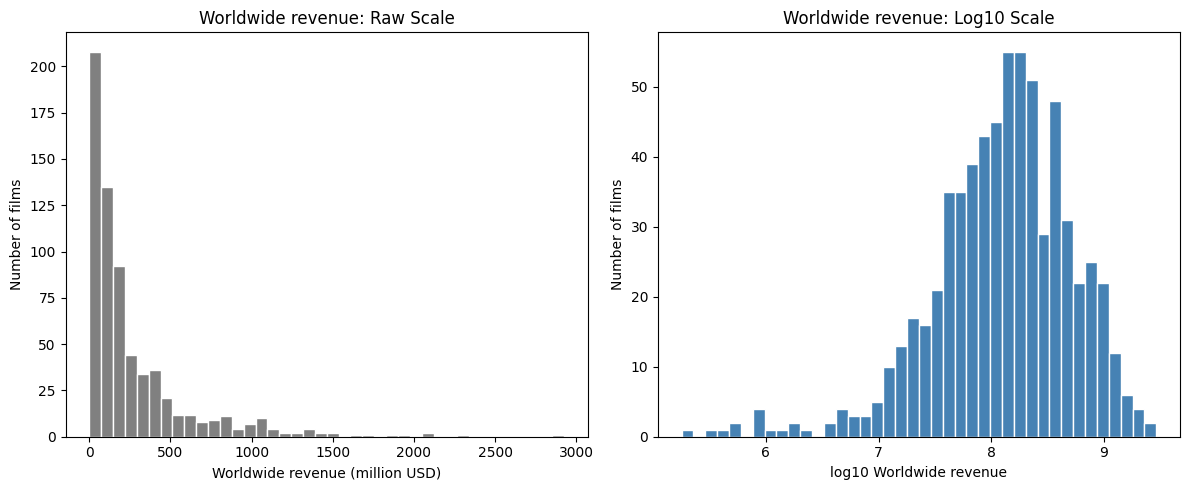

,Number of films,Mean,Median,Skewness
Raw Worldwide revenue,667,2.686126e+08,1.403766e+08,2.799
Log10 Worldwide revenue,667,8.092000e+00,8.147000e+00,-0.933


Raw Worldwide revenue skewness: 2.80
Log10 Worldwide revenue skewness: -0.93

Logging reduces absolute skewness, supporting log10 Worldwide revenue as a candidate model input.



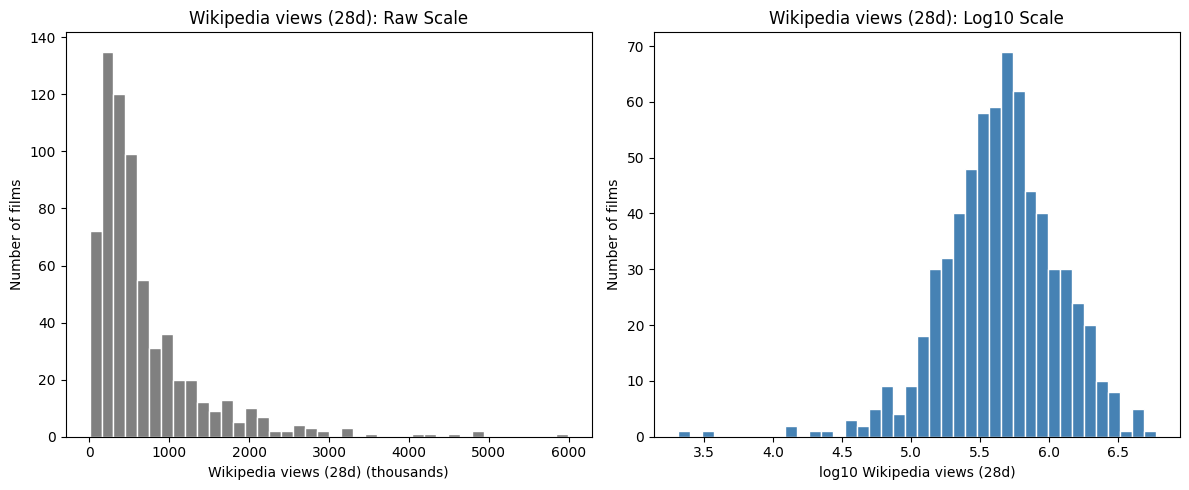

,Number of films,Mean,Median,Skewness
Raw Wikipedia views (28d),667,677827.766,458670.000,2.901
Log10 Wikipedia views (28d),667,5.650,5.662,-0.640


Raw Wikipedia views (28d) skewness: 2.90
Log10 Wikipedia views (28d) skewness: -0.64

Logging reduces absolute skewness, supporting log10 Wikipedia views (28d) as a candidate model input.



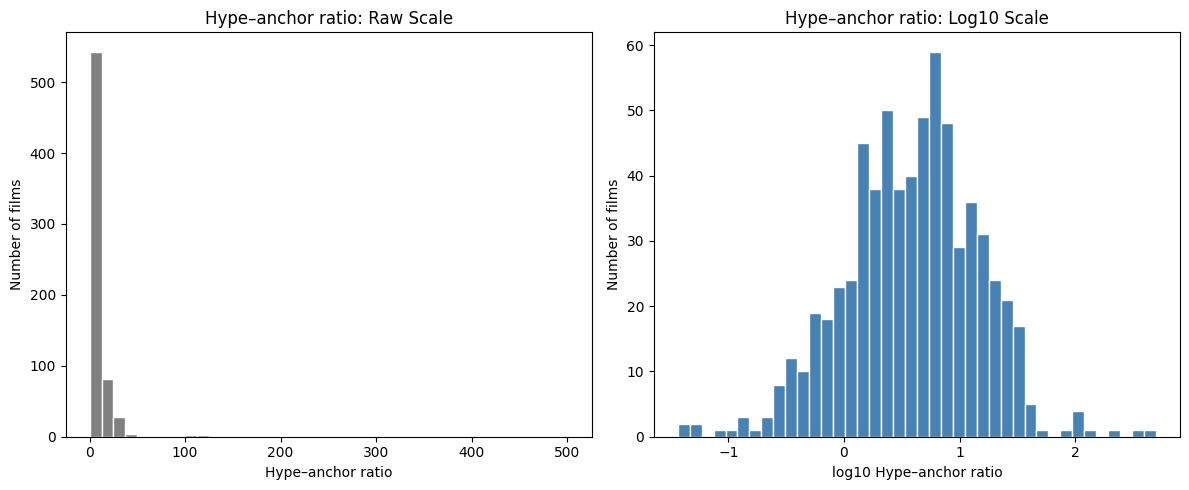

,Number of films,Mean,Median,Skewness
Raw Hype–anchor ratio,667,9.555,4.212,12.330
Log10 Hype–anchor ratio,667,0.582,0.625,-0.159


Raw Hype–anchor ratio skewness: 12.33
Log10 Hype–anchor ratio skewness: -0.16

Logging reduces absolute skewness, supporting log10 Hype–anchor ratio as a candidate model input.



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def compare_log_scale(col, label, unit_div=1, unit_label=''):
    raw = pd.to_numeric(df[col], errors='coerce').replace([np.inf, -np.inf], np.nan)
    raw = raw.loc[raw.gt(0)]
    logged = np.log10(raw)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].hist(raw / unit_div, bins=40, color='gray', edgecolor='white')
    axes[0].set(title=f'{label}: Raw Scale',
                xlabel=f'{label}{unit_label}', ylabel='Number of films')
    axes[1].hist(logged, bins=40, color='steelblue', edgecolor='white')
    axes[1].set(title=f'{label}: Log10 Scale',
                xlabel=f'log10 {label}', ylabel='Number of films')
    plt.tight_layout()
    plt.show()

    summary = pd.DataFrame({
        'Number of films': [raw.count(), logged.count()],
        'Mean': [raw.mean(), logged.mean()],
        'Median': [raw.median(), logged.median()],
        'Skewness': [raw.skew(), logged.skew()],
    }, index=[f'Raw {label}', f'Log10 {label}'])
    display(summary.round(3))

    print(f'Raw {label} skewness: {raw.skew():.2f}')
    print(f'Log10 {label} skewness: {logged.skew():.2f}')
    if abs(logged.skew()) < abs(raw.skew()):
        print(f'\nLogging reduces absolute skewness, supporting log10 {label} '
              'as a candidate model input.\n')
    else:
        print(f'\nLogging does not reduce absolute skewness. '
              f'These results alone do not support logging {label}.\n')


compare_log_scale('revenue_for_analysis', 'Worldwide revenue', 1e6, ' (million USD)')
compare_log_scale('wiki_views_28d', 'Wikipedia views (28d)', 1e3, ' (thousands)')
compare_log_scale('hype_anchor_ratio', 'Hype–anchor ratio')

**Analysis**

A log10 transformation is a reasonable choice for modeling revenue in
our sample of 667 films.

Raw revenue is strongly right-skewed, with skewness of 2.80. Most films
earn relatively modest amounts compared with a few blockbusters, creating
a long right tail. The mean revenue of approximately \$268.6 million is
also substantially higher than the median of \$140.4 million, reflecting
these exceptionally high revenues.

After logging, skewness changes to −0.93. The distribution becomes more
symmetric, although a left tail remains. The transformation compresses
large revenue differences and makes proportional comparisons easier:
\$10 million to \$100 million and \$100 million to $1 billion both represent
a one-unit increase in log10 revenue.

These results support using log10 revenue as a candidate modeling outcome.
They do not establish that the transformed distribution is normal or that
a regression model will fit well. We will also need to examine the fitted
model’s residuals.

Likewise and for similar reasons, wikipedia views and hype-anchor ratio also benefit from a log10 transformation

We can z-score the logged values if standardized units are useful.


In [ ]:
df['log_revenue'] = np.log10(
    pd.to_numeric(df['revenue_for_analysis'], errors='coerce')
    .replace([np.inf, -np.inf], np.nan)
    .where(lambda revenue: revenue.gt(0))
)

df['z_log_revenue'] = (
    df['log_revenue'] - df['log_revenue'].mean()
) / df['log_revenue'].std(ddof=1)

display(
    df[[
        'title',
        'revenue_for_analysis',
        'log_revenue',
        'z_log_revenue'
    ]].head().round(3)
)

,title,revenue_for_analysis,log_revenue,z_log_revenue
3,The Martian,631058917.0,8.800,1.128
5,The Good Dinosaur,332207671.0,8.521,0.684
7,The Revenant,532950503.0,8.727,1.011
10,The Big Short,133346506.0,8.125,0.053
12,Mission: Impossible - Rogue Nation,682716636.0,8.834,1.182


#### EDA 3: Are Wikipedia and Google Trends Attention Correlated?

We examine whether films with higher pre-release Wikipedia pageviews
also tend to have higher Google Trends interest.

We use Spearman’s rank correlation because it measures whether the
indicators tend to increase together without requiring a linear
relationship or normally distributed values.

A coefficient near +1 indicates a strong increasing relationship,
a coefficient near −1 indicates a strong decreasing relationship,
and a coefficient near zero indicates little monotonic association.

The scatterplot uses logarithmic axes to make the highly skewed
attention measures easier to view. Spearman correlation is calculated
from the original values.

,Number of films,Spearman correlation,p-value
0,667,0.398,9.38e-27


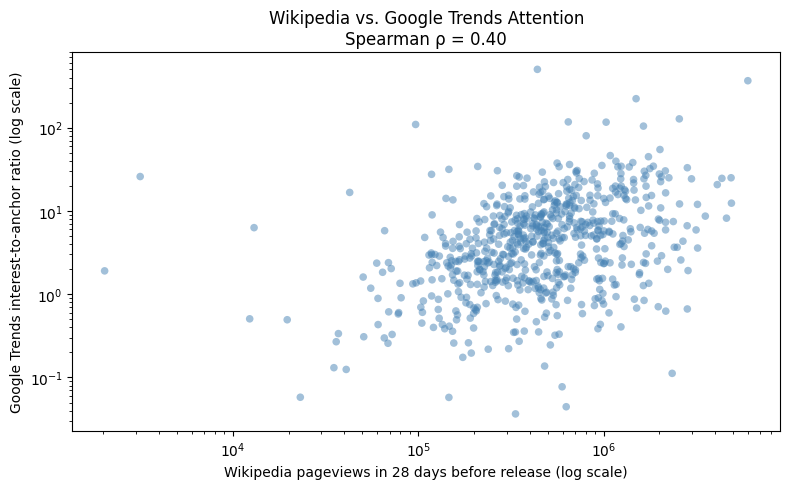

Films used in correlation: 667
Films shown in scatterplot: 667
Spearman correlation: 0.398
Two-sided p-value: 9.38e-27


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr

hype_df = (
    df[['wiki_views_28d', 'hype_anchor_ratio']]
    .apply(pd.to_numeric, errors='coerce')
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

hype_df = hype_df.loc[
    hype_df['wiki_views_28d'].ge(0)
    & hype_df['hype_anchor_ratio'].ge(0)
]

correlation, p_value = spearmanr(
    hype_df['wiki_views_28d'],
    hype_df['hype_anchor_ratio']
)

correlation_summary = pd.DataFrame({
    'Number of films': [len(hype_df)],
    'Spearman correlation': [correlation],
    'p-value': [p_value]
})

display(
    correlation_summary.style.format({
        'Number of films': '{:,.0f}',
        'Spearman correlation': '{:.3f}',
        'p-value': '{:.3g}'
    })
)

plot_df = hype_df.loc[
    hype_df['wiki_views_28d'].gt(0)
    & hype_df['hype_anchor_ratio'].gt(0)
]

plt.figure(figsize=(8, 5))

plt.scatter(
    plot_df['wiki_views_28d'],
    plot_df['hype_anchor_ratio'],
    color='steelblue',
    alpha=0.5,
    s=30,
    edgecolors='none'
)

plt.xscale('log')
plt.yscale('log')

plt.title(
    f'Wikipedia vs. Google Trends Attention\n'
    f'Spearman ρ = {correlation:.2f}'
)

plt.xlabel('Wikipedia pageviews in 28 days before release (log scale)')
plt.ylabel('Google Trends interest-to-anchor ratio (log scale)')

plt.tight_layout()
plt.show()

print(f'Films used in correlation: {len(hype_df):,}')
print(f'Films shown in scatterplot: {len(plot_df):,}')
print(f'Spearman correlation: {correlation:.3f}')
print(f'Two-sided p-value: {p_value:.3g}')

**Analysis**

Across 667 films, Wikipedia pageviews and Google Trends interest show
a moderate positive Spearman correlation (ρ = 0.398). Films with higher
pre-release Wikipedia attention tend to also have higher Google search
interest, although the relationship is far from perfect.

The two-sided p-value of 9.38 × 10⁻²⁷ provides strong evidence against
zero Spearman correlation under the test’s assumptions. However, this
small p-value does not mean the relationship is strong: the coefficient
of 0.398 indicates moderate agreement in the films’ attention rankings.

Both indicators measure online attention, but they reflect different
activities: visiting a Wikipedia article and searching on Google.
Their moderate correlation suggests some overlap without establishing
that they are interchangeable.

We therefore retain Wikipedia and Google Trends as separate candidate
predictors. Further modeling is needed to determine whether either adds
information about revenue beyond the other. This result does not establish
causation or describe how much Google interest increases for each
additional Wikipedia pageview.

#### EDA 4: Do we need to adjust for inflation?

*Why:* Revenue and budget are in nominal dollars. If prices rose steadily from 2015 to 2025, later films could look bigger just because dollars were worth less, and that drift could be mistaken for a hype effect.  
*How to read:* the left and right panels show the median gross and median budget for each release year, in nominal dollars and in 2025 dollars (CPI-U annual averages from the U.S. Bureau of Labor Statistics). If the nominal line climbs while the real line stays flat, inflation is driving the trend.

,films,median_gross_nominal,median_gross_real,median_budget_nominal,median_budget_real
release_year,,,,,
2015,35,155.8,211.6,53.0,72.0
2016,76,169.1,226.8,50.0,67.1
2017,74,211.4,277.6,56.5,74.2
2018,79,160.5,205.8,48.0,61.5
2019,68,152.1,191.5,48.5,61.1
2020,31,40.9,50.9,21.0,26.1
2021,51,90.1,107.1,64.0,76.0
2022,56,112.2,123.4,50.0,55.0
2023,67,130.8,138.2,60.0,63.4


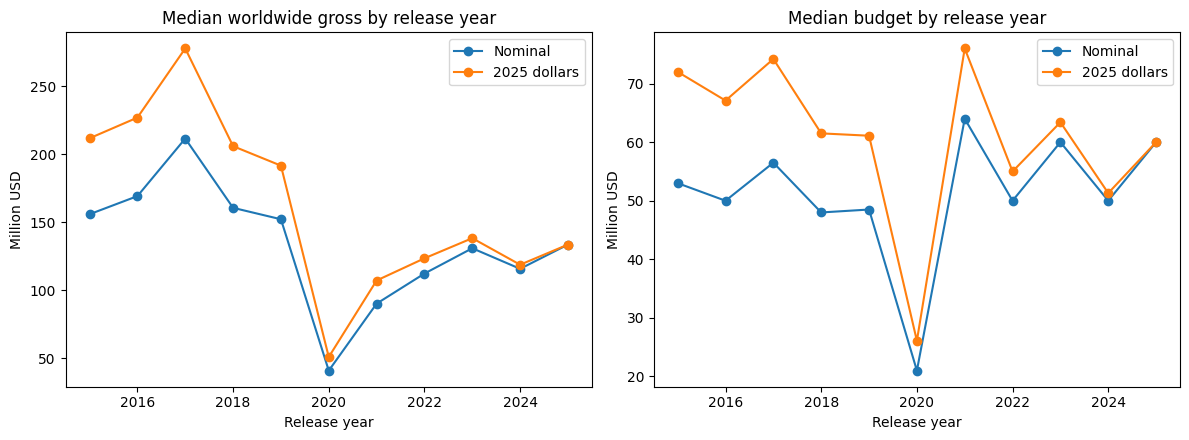

,Variable,Sample,Change per year (%),Spearman rho,p-value
0,"Gross, nominal",All years,-6.113,-0.132,0.001
1,"Gross, nominal",Excl. 2020-21,-5.820,-0.123,0.003
2,"Gross, 2025 $",All years,-9.220,-0.211,0.000
3,"Gross, 2025 $",Excl. 2020-21,-8.963,-0.206,0.000
4,"Budget, nominal",All years,0.835,0.016,0.677
5,"Budget, nominal",Excl. 2020-21,0.667,0.015,0.722
6,"Budget, 2025 $",All years,-2.503,-0.081,0.036
7,"Budget, 2025 $",Excl. 2020-21,-2.692,-0.088,0.034


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression

# CPI-U annual averages (BLS)
cpi = {2015: 237.0, 2016: 240.0, 2017: 245.1, 2018: 251.1, 2019: 255.7,
       2020: 258.8, 2021: 271.0, 2022: 292.7, 2023: 304.7, 2024: 313.7, 2025: 321.9}

infl_df = df.copy()
infl_df['cpi_factor'] = infl_df['release_year'].map(cpi).rdiv(cpi[2025])   # converts to 2025 dollars
infl_df['revenue_real'] = infl_df['revenue_for_analysis'] * infl_df['cpi_factor']
infl_df['budget_real'] = infl_df['budget'] * infl_df['cpi_factor']
infl_df['log_revenue_real'] = np.log10(infl_df['revenue_real'])
infl_df['log_budget_real'] = np.log10(infl_df['budget_real'])

by_year = infl_df.groupby('release_year').agg(
    films=('movie_id', 'size'),
    median_gross_nominal=('revenue_for_analysis', lambda s: s.median() / 1e6),
    median_gross_real=('revenue_real', lambda s: s.median() / 1e6),
    median_budget_nominal=('budget', lambda s: s.median() / 1e6),
    median_budget_real=('budget_real', lambda s: s.median() / 1e6)).round(1)
display(by_year)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (nom, real, title) in zip(axes, [
        ('median_gross_nominal', 'median_gross_real', 'Median worldwide gross by release year'),
        ('median_budget_nominal', 'median_budget_real', 'Median budget by release year')]):
    ax.plot(by_year.index, by_year[nom], marker='o', label='Nominal')
    ax.plot(by_year.index, by_year[real], marker='o', label='2025 dollars')
    ax.set(title=title, xlabel='Release year', ylabel='Million USD')
    ax.legend()
plt.tight_layout()
plt.show()

# Trend in each variable across years (slope of log10 value on year, and Spearman rho)
no_covid = infl_df[~infl_df['release_year'].isin([2020, 2021])]
rows = []
for label, col in [('Gross, nominal', 'log_revenue'), ('Gross, 2025 $', 'log_revenue_real'),
                   ('Budget, nominal', 'log_budget'), ('Budget, 2025 $', 'log_budget_real')]:
    for sample_name, sub in [('All years', infl_df), ('Excl. 2020-21', no_covid)]:
        slope = np.polyfit(sub['release_year'], sub[col], 1)[0]
        rho, p = spearmanr(sub['release_year'], sub[col])
        rows.append({'Variable': label, 'Sample': sample_name,
                     'Change per year (%)': (10 ** slope - 1) * 100,
                     'Spearman rho': rho, 'p-value': p})
display(pd.DataFrame(rows).round(3))

In [ ]:
# Same specification as Preregistration 1, nominal vs. 2025 dollars
m = infl_df[(infl_df['roi'] >= 0.05) & infl_df['log_wiki'].notna()].copy()
genre_counts = m['primary_genre'].value_counts()
m['genre_pooled'] = np.where(m['primary_genre'].map(genre_counts) < 20, 'Other', m['primary_genre'])
controls = pd.get_dummies(m[['genre_pooled', 'season', 'era']], drop_first=True).astype(float)

def wiki_coef(y_col, budget_col, drop_era=False):
    ctrl = controls[[c for c in controls if not (drop_era and c.startswith('era'))]]
    X = pd.concat([m[['log_wiki', budget_col]], ctrl], axis=1)
    y = m[y_col].values
    rng = np.random.RandomState(2950)
    boot = []
    for _ in range(1000):
        idx = rng.randint(0, len(y), len(y))
        boot.append(LinearRegression().fit(X.iloc[idx], y[idx]).coef_[0])
    fit = LinearRegression().fit(X, y)
    return fit.coef_[0], fit.score(X, y), *np.percentile(boot, [5, 95])

results = pd.DataFrame(
    [wiki_coef('log_revenue', 'log_budget'),
     wiki_coef('log_revenue_real', 'log_budget_real'),
     wiki_coef('log_revenue', 'log_budget', drop_era=True),
     wiki_coef('log_revenue_real', 'log_budget_real', drop_era=True)],
    index=['Nominal, with era', '2025 dollars, with era',
           'Nominal, no era', '2025 dollars, no era'],
    columns=['beta_wiki', 'R2', 'boot_p5', 'boot_p95']).round(3)
display(results)

,beta_wiki,R2,boot_p5,boot_p95
"Nominal, with era",0.534,0.626,0.418,0.662
"2025 dollars, with era",0.532,0.634,0.415,0.660
"Nominal, no era",0.537,0.578,0.413,0.668
"2025 dollars, no era",0.510,0.575,0.388,0.639


**What we see.** Prices rose about **36%** between 2015 and 2025 (CPI factor 1.36), but our nominal numbers do not drift upward with them.

- **Gross falls over time, it does not rise.** Median nominal gross peaks in 2017 (\$211M), collapses in 2020 (\$41M), and recovers only to roughly \$115–135M in 2022–2025, below the 2015–2019 level. Nominal gross falls about **6% per year** across all years (Spearman ρ = −0.13, p < 0.001), and about 6% per year even with 2020–21 excluded.
- **Budgets are flat in nominal terms** (+0.8% per year, ρ = 0.02, p = 0.68). The median budget sits near \$50–60M in nearly every year.
- **Converting to 2025 dollars makes the downward pattern steeper** (gross −9% per year, budget −2.5% per year), because it scales earlier years up. It does not reveal a hidden upward trend.
- **CPI adjustment barely changes the model.** With era controls, the Wikipedia coefficient is **0.534 (nominal)** vs. **0.532 (2025 dollars)**, with nearly identical 90% bootstrap intervals ([0.42, 0.66] in both cases). Without era controls it is 0.537 vs. 0.510. The conclusion for Preregistration 1 is the same either way.

**Decision.** The year-to-year variation in our sample is driven by the COVID collapse and slow theatrical recovery, not by inflation. Our `era` dummies already absorb that level shift. We **keep nominal dollars as the primary specification** and add a **CPI-adjusted (2025 dollars) re-run as a fifth preregistered robustness check**.

**Caveats.**
- CPI is a general price index. Ticket prices and exchange rates differ, and worldwide gross is partly earned outside the US, so CPI-U is only an approximation of the right deflator.
- Our sample is selected by popularity, so the downward trend in gross reflects which films are included as well as the box office itself (for example, more streaming-era releases with weaker theatrical runs in recent years).
- Year-level medians for 2015 (35 films) and 2020 (31 films) rest on small samples.

#### EDA 5: How does the genre correspond to net revenue?
How does genre correspond to net revenue?

Why: We wanted to see if different movie genres tend to make more money than others after subtracting their production budgets.

How to read: This bar chart shows the median net revenue for each movie genre in millions of dollars. A higher bar means that movies in that genre generally made more money after subtracting their production budgets.

What we see: Music had the highest median net revenue at around 204 million, followed by adventure at 178 million and animation at 168 million. Romance had the lowest at around 21 million. However, music only had 5 movies in our dataset, so its high median might not represent the genre overall. Adventure and animation had larger sample sizes and still showed high median net revenue. This suggests that movie genre is related to financial performance, although other factors like budget could also play a role.



(667, 62)
['movie_id', 'title', 'original_title', 'original_language', 'release_date_tmdb', 'us_theatrical_date', 'release_year', 'discovery_year', 'budget', 'tmdb_revenue', 'rating', 'vote_count', 'runtime', 'genres', 'imdb_id', 'status', 'tmdb_url', 'first_public_release', 'first_us_home_release', 'days_public_before_us', 'release_timing_ok', 'title_key', 'numbers_revenue', 'numbers_match', 'revenue_for_analysis', 'gross_source', 'wiki_article', 'wiki_match_status', 'wiki_candidate', 'wiki_views_28d', 'wiki_views_28d_main_title', 'wiki_peak_daily', 'wiki_days_observed', 'wiki_titles_counted', 'wiki_status', 'trends_query', 'trends_start', 'trends_end', 'hype_anchor_ratio', 'trends_movie_sum', 'trends_anchor_sum', 'trends_zero_fraction', 'trends_days', 'trend_status', 'trends_method', 'has_valid_outcomes', 'valid_trends', 'trends_low_precision', 'valid_wikipedia', 'analysis_sample', 'log_revenue', 'log_budget', 'log_trends', 'log_wiki', 'roi', 'log_roi', 'release_month', 'season', 'pr

,count,median,mean
primary_genre,,,
Music,5,203670284.0,3.214685e+08
Adventure,46,177615680.0,4.419899e+08
Animation,43,167776646.0,2.865508e+08
Fantasy,22,153094404.0,2.107858e+08
Family,29,137183546.0,3.164404e+08
Science Fiction,42,126096015.5,2.157967e+08
Action,153,118327371.0,2.426124e+08
Mystery,8,112761136.0,1.592470e+08
Comedy,60,65914395.0,1.078975e+08


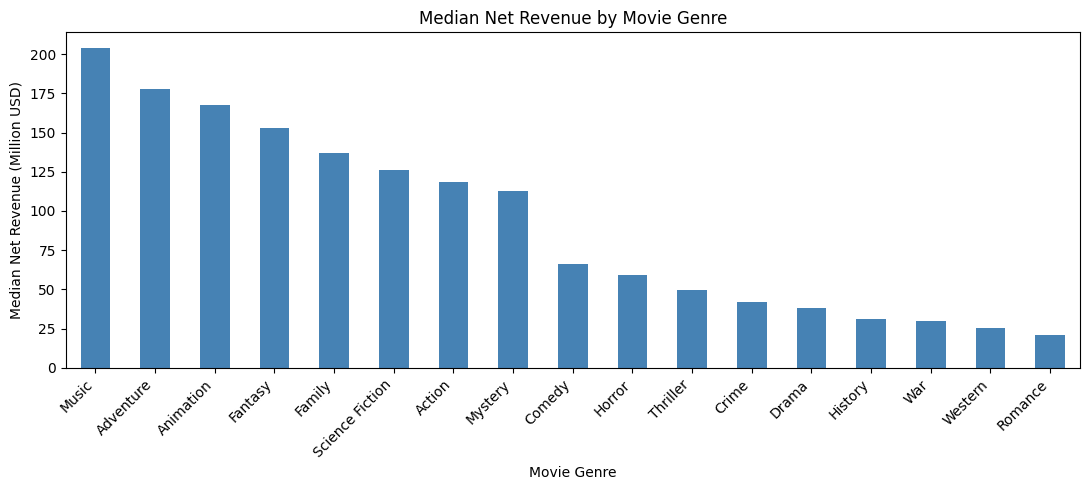

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

print(df.shape)
print(df.columns.tolist())
df.head()


df['net_revenue'] = df['revenue_for_analysis'] - df['budget']

genre_summary = (
    df.groupby('primary_genre')['net_revenue']
    .agg(['count', 'median', 'mean'])
    .sort_values('median', ascending=False)
)

display(genre_summary)


genre_summary['median'].div(1e6).plot(
    kind='bar',
    figsize=(11, 5),
    color='steelblue'
)

plt.title('Median Net Revenue by Movie Genre')
plt.xlabel('Movie Genre')
plt.ylabel('Median Net Revenue (Million USD)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()



#### EDA 6: How does the release season correspond to net revenue?

Why: We wanted to see if the time of year a movie is released affects how much money it makes after subtracting the production budget.

How to read: The bar chart shows the median net revenue for movies released in summer, during the holidays, and in other months. Higher bars mean higher median net revenue.

What we see: Summer releases had the highest median net revenue at around $143 million, followed by holiday releases at $79.5 million and other months at $61.4 million. There were 163 summer movies, 165 holiday movies, and 339 movies released during other months. This suggests that movies released during summer tend to generate higher net revenue. However, this doesn't necessarily mean the release season causes higher revenue, since larger-budget movies might be more likely to be released during summer.

,count,median,mean
season,,,
summer,163,142952373.0,2.548862e+08
holiday,165,79500000.0,2.114529e+08
other,339,61400000.0,1.432855e+08


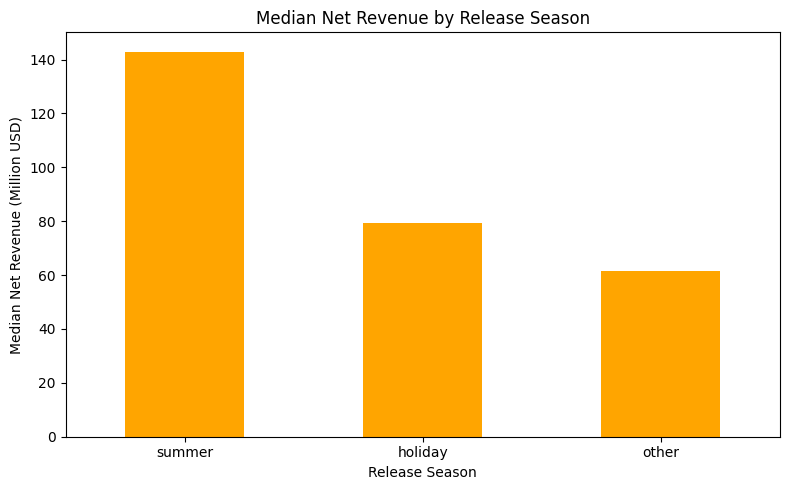

In [ ]:
season_summary = (
    df.groupby('season')['net_revenue']
    .agg(['count', 'median', 'mean'])
    .sort_values('median', ascending=False)
)

display(season_summary)

season_summary['median'].div(1e6).plot(
    kind='bar',
    figsize=(8, 5),
    color='orange'
)

plt.title('Median Net Revenue by Release Season')
plt.xlabel('Release Season')
plt.ylabel('Median Net Revenue (Million USD)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()




#### EDA 7: How do Wikipedia page viewership / Google Trends vary across genres?

Why: We wanted to see typical hype values across different genres for each hype measure, which we guessed may be an approximation for how different audiences engage with movies across our two hype measurement platforms.

How to read: The bar chart shows the median for each genre of Wikipedia page viewership / Google Trends hype-anchor ratio during the 28 day prelease period.

What we see: It seems that Google Trends hype-anchor ratio indicated a slightly more consistent level of attention across all the genres (except for the genres music, western, and mystery, which were of some of the extreme medians and also had low sample sizes compared to the average sample size of 39), where as Wikipedia page viewership varied a bit more genre-by-genre (including the low sample size genres).

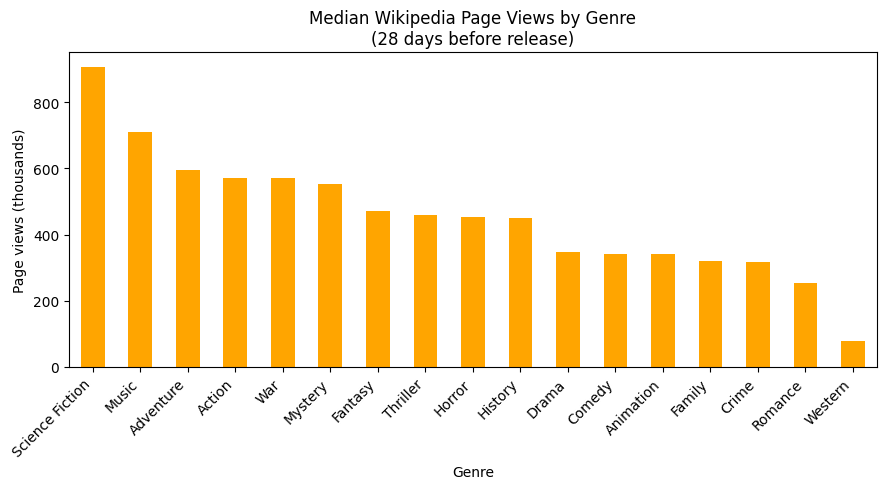

In [ ]:
viewership = (
    df.groupby('primary_genre')['wiki_views_28d']
    .agg(['count', 'median', 'mean'])
    .sort_values('median', ascending=False)
)

col = 'wiki_views_28d'

wiki_dev = (
    df.groupby('primary_genre')[col]
    .agg(count='count', genre_median='median')
)

# avg_median = wiki_dev['genre_median'].mean()
# sd_median = wiki_dev['genre_median'].std()

# wiki_dev['diff_from_avg_median'] = wiki_dev['genre_median'] - avg_median
# wiki_dev['sd_from_avg_median'] = wiki_dev['diff_from_avg_median'] / sd_median
# wiki_dev = wiki_dev.sort_values('sd_from_avg_median', ascending=False)

# print(f'Average genre median: {avg_median:,.0f} views | SD of genre medians: {sd_median:,.0f} views')
# display(wiki_dev.round({'genre_median': 0, 'diff_from_avg_median': 0, 'sd_from_avg_median': 2}))

ax = viewership['median'].div(1e3).plot(
    kind='bar',
    figsize=(9, 5),
    color='orange'
)

ax.set_title('Median Wikipedia Page Views by Genre\n(28 days before release)')
ax.set_xlabel('Genre')
ax.set_ylabel('Page views (thousands)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

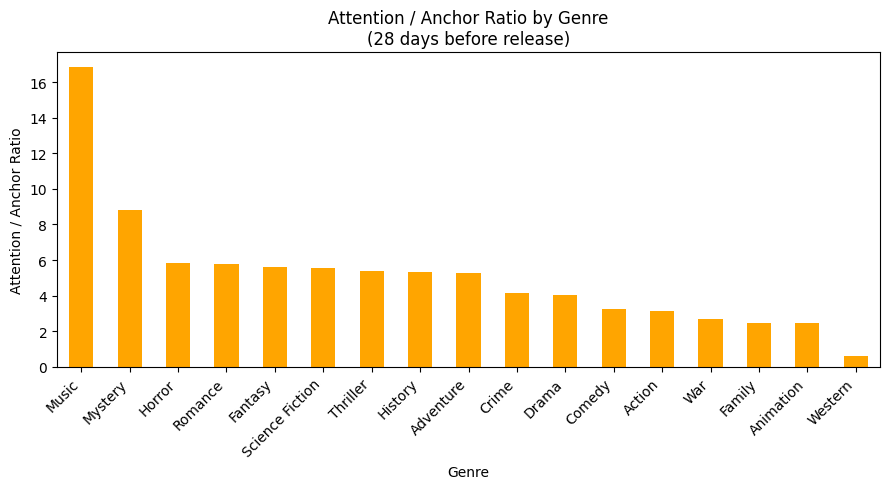

In [ ]:
viewership = (
    df.groupby('primary_genre')['hype_anchor_ratio']
    .agg(['count', 'median', 'mean'])
    .sort_values('median', ascending=False)
)

col = 'hype_anchor_ratio'

genre_dev = (
    df.groupby('primary_genre')[col]
    .agg(count='count', genre_median='median')
)

# avg_median = genre_dev['genre_median'].mean()
# sd_median = genre_dev['genre_median'].std()

# genre_dev['diff_from_avg_median'] = genre_dev['genre_median'] - avg_median
# genre_dev['sd_from_avg_median'] = genre_dev['diff_from_avg_median'] / sd_median
# genre_dev = genre_dev.sort_values('sd_from_avg_median', ascending=False)

# print(f'Average genre median: {avg_median:.3f} | SD of genre medians: {sd_median:.3f}')
# display(genre_dev.round(3))

ax = viewership['median'].plot(
    kind='bar',
    figsize=(9, 5),
    color='orange'
)

ax.set_title('Attention / Anchor Ratio by Genre\n(28 days before release)')
ax.set_xlabel('Genre')
ax.set_ylabel('Attention / Anchor Ratio')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
sample = df[df['analysis_sample']]

genre_counts = sample['primary_genre'].value_counts().rename('count').to_frame()

avg_count = genre_counts['count'].mean()
sd_count = genre_counts['count'].std()

genre_counts['diff_from_avg'] = genre_counts['count'] - avg_count
genre_counts['sd_from_avg'] = genre_counts['diff_from_avg'] / sd_count

print(f'Movies in sample: {len(sample)} | Avg per genre: {avg_count:.1f} | SD: {sd_count:.1f}')
display(genre_counts.round(2))

Movies in sample: 667 | Avg per genre: 39.2 | SD: 40.2


,count,diff_from_avg,sd_from_avg
primary_genre,,,
Action,153,113.76,2.83
Horror,90,50.76,1.26
Drama,90,50.76,1.26
Comedy,60,20.76,0.52
Adventure,46,6.76,0.17
Animation,43,3.76,0.09
Science Fiction,42,2.76,0.07
Family,29,-10.24,-0.25
Crime,28,-11.24,-0.28


Here, we see that music, western, and mystery (some of the extreme medians) had low sample sizes compared to the average sample size of 39.

#### EDA 8: How do audience satisfaction / global box office gross correspond to movie budget?

Why: We wanted to see whether the movie budget corresponded more strongly to audience satisfaction or global box office gross. We suspect that larger movie budgets allow the movie producers to allocate more resources towards "stirring up hype" in online spaces through ads, high-visbility trailers, etc. This could serve as an indication for how our pre-release hype correlates to audience satisfaction / global box office gross.

How to read: The scatterplot shows TMDb rating / global box office gross against the movie budget for each movie in our final dataset.

What we see: The correlation between audience rating and budget (0.018) is much weaker than the correlation between betweeen revenue and budget (0.579).

Movies used: 667
Correlation (log10 budget vs rating): 0.018


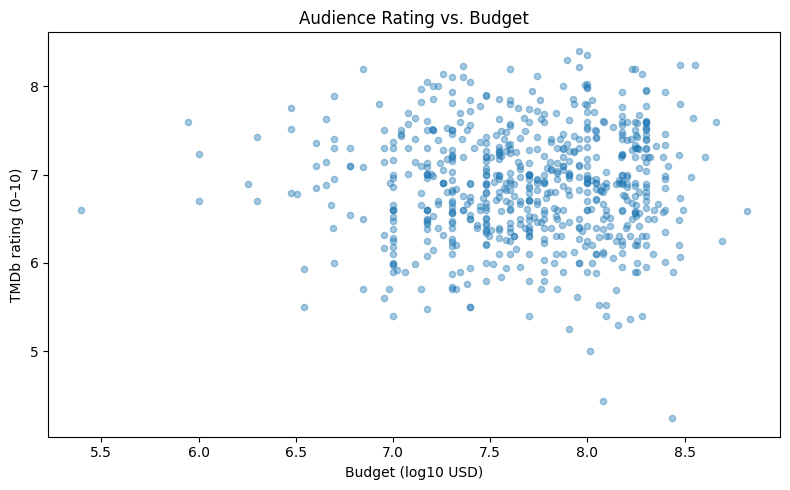

In [ ]:
MIN_VOTES = 50

sub = df[(df['budget'] > 0) & (df['vote_count'] >= MIN_VOTES)].dropna(subset=['budget', 'rating'])
sub = sub.assign(log_budget=np.log10(sub['budget']))

corr = sub['log_budget'].corr(sub['rating'])
print('Movies used:', len(sub))
print(f'Correlation (log10 budget vs rating): {corr:.3f}')

ax = sub.plot.scatter(x='log_budget', y='rating', alpha=0.4, figsize=(8, 5))
ax.set_title('Audience Rating vs. Budget')
ax.set_xlabel('Budget (log10 USD)')
ax.set_ylabel('TMDb rating (0–10)')
plt.tight_layout()
plt.show()

Movies used: 667
Correlation (log10 budget vs log10 revenue): 0.579


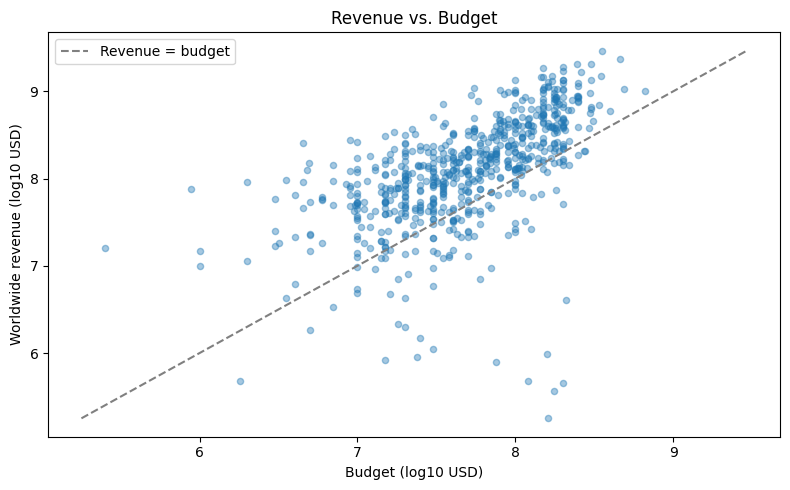

In [ ]:
sub = df[(df['budget'] > 0) & (df['tmdb_revenue'] > 0)].dropna(subset=['budget', 'tmdb_revenue'])
sub = sub.assign(log_budget=np.log10(sub['budget']),
                 log_revenue=np.log10(sub['tmdb_revenue']))

corr = sub['log_budget'].corr(sub['log_revenue'])
print('Movies used:', len(sub))
print(f'Correlation (log10 budget vs log10 revenue): {corr:.3f}')

ax = sub.plot.scatter(x='log_budget', y='log_revenue', alpha=0.4, figsize=(8, 5))
lims = [sub[['log_budget', 'log_revenue']].min().min(), sub[['log_budget', 'log_revenue']].max().max()]
ax.plot(lims, lims, '--', color='gray', label='Revenue = budget')
ax.set_title('Revenue vs. Budget')
ax.set_xlabel('Budget (log10 USD)')
ax.set_ylabel('Worldwide revenue (log10 USD)')
ax.legend()
plt.tight_layout()
plt.show()

## Part 2: Preregistration of Analyses

### Preregistration Statement 1

**Hypothesis 1: Controlling for budget, genre, and release season, pre-release Google Trends interest predicts worldwide box-office gross better than pre-release English Wikipedia pageviews.** That is, we create two distinct but identical multiple linear regression models. Both include the features: budget, genre, and release season. However, model A includes log Google Trends hype anchor ratio as its hype metric, and model B includes log Wiki views 28d as its hype metric. We will train both on a subset of our data, and then test for precision error using Root Mean Square Error (RMSE) on a held out set. The split will be 85/15 for training vs testing. The difference between the two models will be attributed to the feature that describes pre-release online attention.

**Why we expect this.** The Google Trends data may reflect a broader audience of viewers, while the Wikipedia page viewership may reflect a more niche audience.

We see this in **EDA 7**, which shows a somewhat consistent median hype-anchor ratio across different genres (except for music genre - which had 5 sample compared to the avg of 39 samples per genre), while the median Wikipedia page viewership varies more heavily across from genre to genre. This suggests that Google trends ratio may be a superior metric for capturing median "hype" across all different kinds of audiences, whereas Wikipedia (a more niche platform than Google), might bias towards certain genres.


**Key concepts defined.**
- *Wikipedia attention* = `wiki_views_28d`: human-user daily views of the film's verified article plus its redirects, summed over release − 28 days to release − 1 day.
- *Google Trends hype-anchor ratio*: The hype–anchor ratio is a film’s total Google Trends interest over the 28 days before its US release divided by the total interest of a fixed anchor term queried alongside it, which puts every film’s pre-release search attention on a common scale even though Trends rescales each request independently. In other words, we can write this as:
$$\text{hype–anchor ratio} = \frac{\sum_{\text{28 days}} \text{film interest}}{\sum_{\text{28 days}} \text{anchor interest}}$$
where the film interest of the day is the scaled value that Google Trends gives us for our movie term and anchor term is the corresponding scaled value of the anchor term we queried. The anchor term is th

- *Box office gross* = worldwide gross TMDb data.


**Analysis.**

Model A: Google Trends

$$\log_{10}(\text{gross}) = \beta_0 + \beta_1 \log_{10}(\text{hype_anchor_ratio}) + \beta_2 \log_{10}(\text{budget}) + \gamma_{\text{genre}} + \delta_{\text{season}} + \varepsilon$$

Model B: Wikipedia pageviews
$$\log_{10}(\text{gross}) = \beta_0 + \beta_1 \log_{10}(\text{wiki_views_28d}) + \beta_2 \log_{10}(\text{budget}) + \gamma_{\text{genre}} + \delta_{\text{season}} + \varepsilon$$

*For class variables like genre and season, we create dummy variables for each class (except one)*

**Formal Null Pairing**

H₀: The Google Trends model and the Wikipedia model predict worldwide gross equally well.

H₁: The Google Trends model predicts worldwide gross better than the Wikipedia model.


### Preregistration Statement 2

**Hypothesis 2:  Prerelease online hype corresponds more strongly to worldwide box-office gross than to audience satisfaction.** We create a prerelease online hype metric that combines Google Trends interest and Wikipedia pageviews. We do this by first taking log10 of Google Trends interest and Wikipedia pageviews, since we have already observed that this is the appropriate scale (EDA 3), then z-scoring the two measures, and then averaging the z-score of the two measures for each movie. This becomes the combined prerelease online hype metric. We will define audience satisfaction as average audience rating. We then take Spearman correlation.

**Why we expect this.** We assume many people buy tickets to movies because of strong advertising or pre-release online hype, even if the movie itself is not a "quality" (highly rated) film afterwards. This assumption, paired with the EDA 8 showing that budget correlates much more strongly with revenue than the audience satisfaction, indicates the possibility that a well-resourced movie that has a greater capacity to stir up "online hype" would correlate more strongly to revenue than audience satisfaction.

**Key concepts defined.**

- *Prerelease online hype*:  We create a prerelease online hype metric that combines Google Trends interest and Wikipedia pageviews. We do this by first taking log10 of Google Trends interest and Wikipedia pageviews, since we have already shown that this is the appropriate scale (EDA 3), then z-scoring the two measures, and then averaging the z-score of the two measures for each movie.
- *Audience satisfaction:* We will define audience satisfaction as average audience rating from the TMDb ratings
- *Box office gross* = worldwide gross TMDb data.


**Analysis.**
We restrict the analysis to films in the analysis sample with valid Google Trends, Wikipedia, gross, and rating data, so that both correlations are computed on the same set of films. To reduce noise from sparsely rated films, we also require a minimum number of TMDb votes (e.g., 50). For each film, we compute the combined prerelease online hype metric as described above. We then calculate two Spearman rank correlations: ρ_gross, between hype and worldwide box-office gross, and ρ_rating, between hype and average audience rating. Spearman correlation is used because it captures any consistently increasing relationship without assuming linearity and is robust to the extreme values common in box-office data; because it depends only on ranks, logging gross does not change the result. Since both correlations share the same hype variable and are computed on the same films, they are not independent, so we test the difference Δ = ρ_gross − ρ_rating with a bootstrap. We resample films with replacement 10,000 times, recompute both correlations and their difference on each resample, and take the 2.5th and 97.5th percentiles as a 95% confidence interval for Δ. We reject H₀ in favor of H₁ if this interval lies entirely above zero, meaning hype is more strongly associated with gross than with satisfaction.

**NOTE**: Bootstrap has not as of now covered been covered in class, though we decided to include it in our project for robustness. This allows us to have 95%. confidence interval that the difference (i.e. which one is greater) is correct.

**Formal Null Pairing**

H₀: Pre-release online hype corresponds to worldwide box-office gross and to audience satisfaction equally.

H₁:  Prerelease online hype corresponds more strongly to worldwide box-office gross than to audience satisfaction

## Questions for Reviewers

**1**. Should we expand our data to include other sources of prerelease online hype? If so, is there a way that we can gather explicitly "pre-release" data for sources like YouTube or Reddit, where current data includes "post-release" data as well?

**2**. Do we have enough data to train our models for pregistered statement 1? Our final dataset includes ~650 entries, and we chose an 85/15 test split. Is this an acceptable split?

**3**. Is our combined metric for prerelease hype in pregistered statement 2 the best way of combining the Google Trends hype-anchor-ratio and Wikipedia pageviews? Are there better ways of combining two metrics into a single metric?

**4**. How do we decide which loss function we should use to train our models for pregistered statement 1?



### References

- Gebru, T., et al. (2018). *Datasheets for Datasets.* arXiv:1803.09010.
- Asur, S., & Huberman, B. A. (2010). Predicting the future with social media. *IEEE/WIC/ACM WI-IAT.*
- U.S. Bureau of Labor Statistics. (2026). *Consumer Price Index for All Urban Consumers (CPI-U).* U.S. Department of Labor. https://www.bls.gov/cpi/

### Generative AI Use Reflection

**Tool used.** Claude (Anthropic), through the Claude app, during October 2026.

**What we used it for**
- **Restructuring our pipeline.** Our original collection notebook mixed API calls with cleaning. We asked Claude to separate the two, so this notebook contains only cleaning steps that read our saved raw files. It drafted the nine cleaning steps and the EDA code from our existing notebook, keeping the rules we had already chosen (the 28-day window, the release-timing screen, the low-precision Trends flag, The Numbers matching rules).

- **Suggesting changes.** Claude suggested flagging streaming originals with token theatrical runs (`limited_theatrical_flag`), after it noticed *Red Notice* and *The Irishman* in our "hyped but flopped" table. It also suggested switching our preregistered significance tests to a bootstrap, so they use methods from this course.
- **Formatting and debugging.** It fixed markdown tables that overflowed in Colab and dollar signs that Colab rendered as math, and it simplified hard-to-read code (for example, rewriting The Numbers matching loop as a small function).
- **Understanding code generated by AI** Asking questions to further understand what the AI output actually does. We also used it to learn more about concepts unclear to us.
- **Used to collect information about our data sources** Asking for information about BLS when evaluating it as a data source, and writing up the BLS description.
- **Used generate analysis for Pregistered statement 2** While we knew that we wanted to include correlation between them, AI suggested bootstrapping, spearman correlation, and noise filter with 50 min votes. It was used to write up the description for the preregistration statement.

**What we did ourselves**
- Chose the topic, the data sources, and the decision to focus on box office as the outcome.
- Collected all raw data with our own API keys and parsed The Numbers records.
- Ran the full notebook on our real data and checked that the printed results match the numbers quoted in the text.
- Reviewed each AI-drafted section and decided what to keep, change, or drop.

**How we checked the AI's work**
- **Code:** For collection and cleaning, Claude tested the code only on mock data shaped like our files; it had no access to our real data. We ran it on the real files and compared the Step 9 summary with the figures in the text.

- **Mistakes we caught:**
  - A code comment said "log10" when the code used log(1 + x).
  - A text edit accidentally deleted spaces after bold words.
  - A date parser failed on mixed date formats in the mock data.
  
  Each was fixed before submission. These showed us that AI output looks finished even when it isn't, so every line needs reading.

**Reflection.** AI saved us the most time on structure and presentation: turning a working but messy notebook into documented, reproducible steps, and drafting clear explanations of each decision. It was least reliable on details that need our data or our judgment. It could not see our real results, and some of its first drafts stated things more confidently than our evidence supports, so we softened claims (for example, that hype "predicts" rather than "causes" box office). The judgment calls are ours and we can defend each one: which films to exclude, which hypotheses to preregister, and how to read a weak Trends signal.